# matplotlib: the axes of `plt.subplots(n, m)` keep their type

matplotlib types `fig, axes = plt.subplots(3, 1)` as `tuple[Figure, Any]`: at runtime `axes` is a numpy
array of `Axes`, and numpy's types can't say what an object array holds. So `axes`, `axes[0]`,
`for ax in axes` and every `ax.set_title(...)`, `ax.imshow(...)` after them are `Any`: no completion, no
errors. The rest of matplotlib is already typed (`plt.subplots()` with no grid is `tuple[Figure, Axes]`,
`ax.plot(...)` is `list[Line2D]`, `ax.imshow(...)` is `AxesImage`, ...).

When the call says the grid's shape, the fork gives the array its `Axes` type and its number of dimensions:
literal `nrows` and `ncols` (numpy drops the dimensions of size 1, so `plt.subplots(3, 1)` is 1-D and
`plt.subplots(2, 3)` is 2-D), or `squeeze=False` (always 2-D). Indexing down to one plot, iterating,
`zip(axes, ...)`, unpacking, `.flat`, `.ravel()`, `.flatten()` and `.tolist()` give `Axes`.

Hover shows the array as `ndarray[Axes, ndim=1]`. That spelling is display only, not valid in annotations.
Each `reveal_type(...)` has the checker's result in a comment (VS Code shows it as a note), and prints the
runtime type when run.

In [1]:
from typing import reveal_type

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.figure import Figure

x = np.linspace(0, 2 * np.pi, 100)

## 🆕 A column of plots: `plt.subplots(3, 1)` is a 1-D array of `Axes`

Runtime type is 'ndarray'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'Axes'


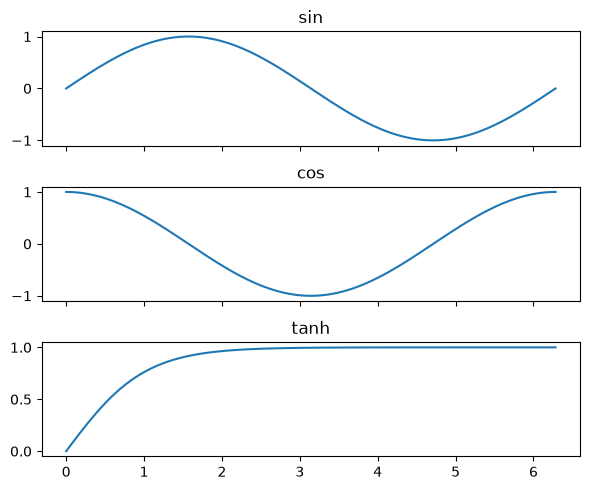

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(6, 5), sharex=True)
reveal_type(axes)  # ndarray[Axes, ndim=1]   (stock: Any)
reveal_type(axes[0])  # Axes   (stock: Any)
for ax, f in zip(axes, (np.sin, np.cos, np.tanh)):
    reveal_type(ax)  # Axes   (stock: Any)
    ax.plot(x, f(x))
    ax.set_title(f.__name__)
fig.tight_layout()

Unpacking works too, since the fork knows what iterating the array gives.

Runtime type is 'Axes'


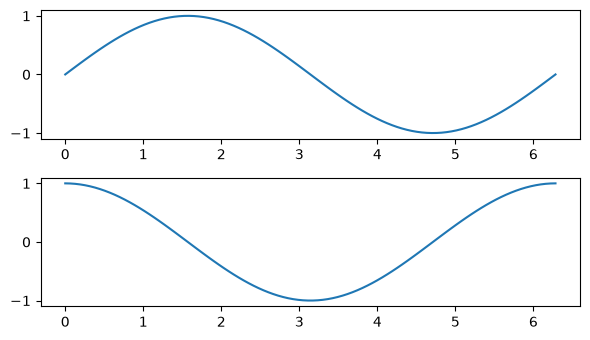

In [3]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(6, 3.5))
reveal_type(top)  # Axes   (stock: Any)
top.plot(x, np.sin(x))
bottom.plot(x, np.cos(x))
fig.tight_layout()

## 🆕 A grid: `plt.subplots(2, 3)` is a 2-D array of `Axes`

`grid[0, 1]` is one plot; `grid[0]` and `grid[:, 0]` are a row and a column (1-D arrays); `.flat`, `.ravel()`
and `.flatten()` go through every plot.

Runtime type is 'ndarray'
Runtime type is 'Axes'
Runtime type is 'ndarray'
Runtime type is 'ndarray'
Runtime type is 'ndarray'
Runtime type is 'ndarray'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'ndarray'
Runtime type is 'list'


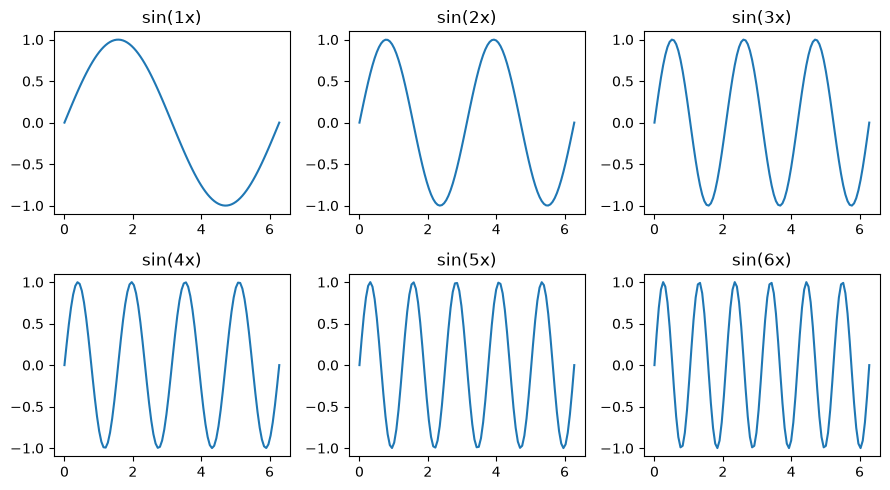

In [4]:
fig, grid = plt.subplots(2, 3, figsize=(9, 5))
reveal_type(grid)  # ndarray[Axes, ndim=2]   (stock: Any)
reveal_type(grid[0, 1])  # Axes
reveal_type(grid[0])  # ndarray[Axes, ndim=1]: the first row
reveal_type(grid[:, 0])  # ndarray[Axes, ndim=1]: the first column
for row in grid:
    reveal_type(row)  # ndarray[Axes, ndim=1]
for k, ax in enumerate(grid.flat):
    reveal_type(ax)  # Axes
    ax.plot(x, np.sin((k + 1) * x))
    ax.set_title(f'sin({k + 1}x)')
reveal_type(grid.ravel())  # ndarray[Axes, ndim=1]
reveal_type(grid.tolist())  # list[list[Axes]]
fig.tight_layout()

## 🆕 Sizes that come from data: `squeeze=False`

With the default `squeeze=True` the array's shape depends on the values: `plt.subplots(1, len(pics))` is
1-D, except that one picture gives a single `Axes` (and `axes[0]` then crashes). So the fork can't type it
(it stays `Any`, below). `squeeze=False` always gives a 2-D array, whatever the sizes, so it is typed, and
the code no longer breaks for one picture.

Runtime type is 'ndarray'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'Axes'
Runtime type is 'Axes'


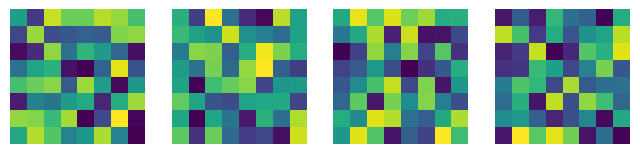

In [5]:
pics = [np.random.rand(8, 8) for _ in range(4)]
fig, grid = plt.subplots(1, len(pics), figsize=(8, 2.2), squeeze=False)
reveal_type(grid)  # ndarray[Axes, ndim=2]   (stock: ndarray[tuple[Any, ...], dtype[Any]])
for ax, pic in zip(grid[0], pics):
    reveal_type(ax)  # Axes
    ax.imshow(pic)
    ax.axis('off')

## 🆕 `fig.subplots(...)` too

Runtime type is 'ndarray'


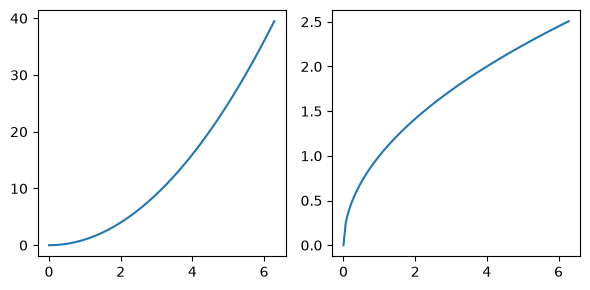

In [6]:
fig = plt.figure(figsize=(6, 3))
pair = fig.subplots(1, 2)
reveal_type(pair)  # ndarray[Axes, ndim=1]   (stock: Any)
pair[0].plot(x, x**2)
pair[1].plot(x, np.sqrt(x))
fig.tight_layout()

## What stays as today

A single plot is already typed. Sizes that aren't literal numbers (with the default `squeeze=True`), a `squeeze`
that isn't a literal, and anything else on the array (`.shape`, `.T`, `.reshape(...)`, an index with more
numbers than the array has dimensions) are as matplotlib and numpy declare them.

In [7]:
fig, ax = plt.subplots()
reveal_type(ax)  # Axes: already, in stock too
n = len(pics)
fig, axes = plt.subplots(3, n)
reveal_type(axes)  # Any: 1-D or 2-D depending on n
plt.close('all')

Runtime type is 'Axes'
Runtime type is 'ndarray'


## 🆕 Errors that stock basedpyright misses (inside a function so this notebook runs)

With `axes` typed, a misspelt method or a wrong argument on a plot is an error. In stock both lines are
`Any.something`, so nothing is reported.

In [8]:
def _errors() -> None:
    fig, axes = plt.subplots(3, 1)
    axes[0].set_titel('top')  # error: Cannot access attribute "set_titel" for class "Axes"
    axes[1].set_xlim(0, 'ten')  # error: "Literal['ten']" is not assignable to "float | None"